## Outline
1.   This notebok uses Bikes rental dataset for regression. It has highly correlated features. For linear regression weights of these features can become inadequately high, which influence on robustness and performance of the model.
2. Example: the usage of Lasso or Ridge regularization can help to supress these weights and to make the model robust.
3. Example: Linear Regression overfitting after applying polynomization by increasing the order of linear polynom.



In [ ]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


#### Data from the bike rental point

In [ ]:
df = pd.read_csv("/content/drive/My Drive/bikes_rental.csv")
df.head()

,Unnamed: 0,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed(mph),windspeed(ms),cnt
0,0,1,0,1,0,6,0,2,14.110847,18.18125,80.5833,10.749882,4.805490,985
1,1,1,0,1,0,0,0,2,14.902598,17.68695,69.6087,16.652113,7.443949,801
2,2,1,0,1,0,1,1,1,8.050924,9.47025,43.7273,16.636703,7.437060,1349
3,3,1,0,1,0,2,1,1,8.200000,10.60610,59.0435,10.739832,4.800998,1562
4,4,1,0,1,0,3,1,1,9.305237,11.46350,43.6957,12.522300,5.597810,1600


For each day of rental, the following features are known (as indicated in the data source):
* _season_: 1 - spring, 2 - summer, 3 - autumn, 4 - winter
* _yr_: 0 - 2011, 1 - 2012
* _mnth_: 1 to 12
* _holiday_: 0 - no holiday, 1 - there is a holiday
* _weekday_: 0 to 6
* _workingday_: 0 - non-working day, 1 - working day
* _weathersit_: rating of the favorable weather from 1 (clean, clear day) to 4 (heavy rain, fog)
* _temp_: temperature in Celsius
* _atemp_: "Feels like" temperature in Celsius
* _hum_: humidity
* _windspeed (mph) _: wind speed in miles per hour
* _windspeed (ms) _: wind speed in meters per second

TARGET:
* _cnt_: the number of rented bicycles


In [ ]:
df.corr()

,Unnamed: 0,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed(mph),windspeed(ms),cnt
Unnamed: 0,1.000000,0.412224,0.866025,0.496702,0.016145,-0.000016,-0.004337,-0.021477,0.150580,0.152638,0.016375,-0.112620,-0.112620,0.628830
season,0.412224,1.000000,-0.001844,0.831440,-0.010537,-0.003080,0.012485,0.019211,0.334315,0.342876,0.205445,-0.229046,-0.229046,0.406100
yr,0.866025,-0.001844,1.000000,-0.001792,0.007954,-0.005461,-0.002013,-0.048727,0.047604,0.046106,-0.110651,-0.011817,-0.011817,0.566710
mnth,0.496702,0.831440,-0.001792,1.000000,0.019191,0.009509,-0.005901,0.043528,0.220205,0.227459,0.222204,-0.207502,-0.207502,0.279977
holiday,0.016145,-0.010537,0.007954,0.019191,1.000000,-0.101960,-0.253023,-0.034627,-0.028556,-0.032507,-0.015937,0.006292,0.006292,-0.068348
weekday,-0.000016,-0.003080,-0.005461,0.009509,-0.101960,1.000000,0.035790,0.031087,-0.000170,-0.007537,-0.052232,0.014282,0.014282,0.067443
workingday,-0.004337,0.012485,-0.002013,-0.005901,-0.253023,0.035790,1.000000,0.061200,0.052660,0.052182,0.024327,-0.018796,-0.018796,0.061156
weathersit,-0.021477,0.019211,-0.048727,0.043528,-0.034627,0.031087,0.061200,1.000000,-0.120602,-0.121583,0.591045,0.039511,0.039511,-0.297391
temp,0.150580,0.334315,0.047604,0.220205,-0.028556,-0.000170,0.052660,-0.120602,1.000000,0.991702,0.126963,-0.157944,-0.157944,0.627494
atemp,0.152638,0.342876,0.046106,0.227459,-0.032507,-0.007537,0.052182,-0.121583,0.991702,1.000000,0.139988,-0.183643,-0.183643,0.631066


There are two pairs of strongly correlated columns in the matrix:
"temp" and "atemp" - and two windspeeds (in mph and in ms)

(because this is just a translation of one unit to another).

This fact negatively affects the training of the linear model.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle

In [ ]:
df_shuffled = shuffle(df, random_state=0)
scaler = StandardScaler()
X = scaler.fit_transform(df_shuffled[df_shuffled.columns[:-1]])
y = df_shuffled["cnt"]

Let's train linear regression on our data and look at the feature weights.

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
Classificator_LR = LinearRegression().fit(X,y)

print(np.array(df.columns)[1:-1])
df_LR_coefs = pd.DataFrame(data = np.array([np.array(df_shuffled.columns)[1:-1], Classificator_LR.coef_[1:]]).T, columns = [['feature', 'Weight']])
df_LR_coefs

['season' 'yr' 'mnth' 'holiday' 'weekday' 'workingday' 'weathersit' 'temp'
 'atemp' 'hum' 'windspeed(mph)' 'windspeed(ms)']


,feature,Weight
0,season,569.783766
1,yr,2546.629242
2,mnth,734.760419
3,holiday,-87.433496
4,weekday,137.340421
5,workingday,57.303374
6,weathersit,-337.103041
7,temp,395.406868
8,atemp,555.376083
9,hum,-137.082611


The weights for linearly dependent features are significantly higher in absolute values than for others.

Linear regression with L1 (Lasso) and L2 (Ridge) regularizations:

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


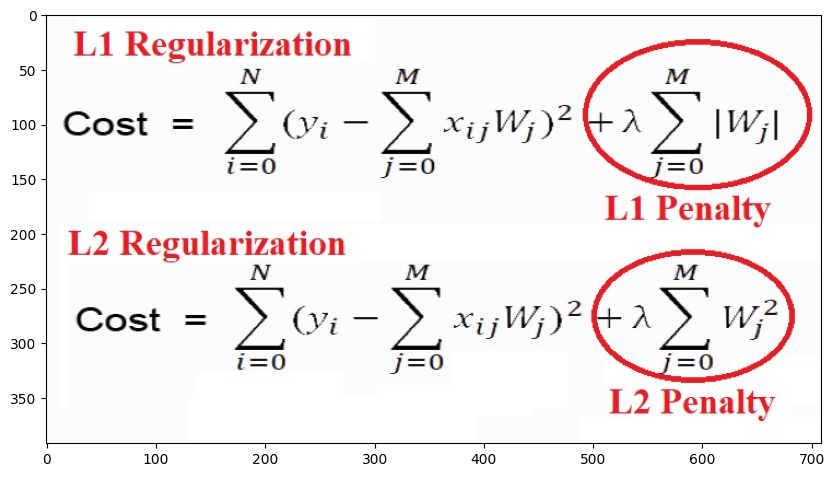

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
img = mpimg.imread('/content/drive/My Drive/L1-L2.png')
plt.figure(figsize = (10,20))
plt.imshow(img)
plt.show()

In [ ]:
from sklearn.linear_model import Lasso, Ridge
# Ridge Regressor - L2 Penalty
# Lasso Regressor - L1 Penalty

In [ ]:
Ridge_LR = Ridge()
Ridge_LR.fit(X,y)

df_Ridge_coefs = pd.DataFrame(data = np.array([np.array(df.columns)[1:-1], Ridge_LR.coef_[1:]]).T, columns = [['feature', 'Weight']])
df_Ridge_coefs

,feature,Weight
0,season,563.416889
1,yr,1370.998924
2,mnth,70.021698
3,holiday,-86.868696
4,weekday,138.081012
5,workingday,56.092977
6,weathersit,-333.989578
7,temp,392.05763
8,atemp,560.205063
9,hum,-143.116121


## Main adantage of Lasso L₁ regression: L₁ penalty forces some coefficients to shrink all the way to zero. This completely removes irrelevant or redundant features from the model.

In [ ]:
Lasso_LR = Lasso()
Lasso_LR.fit(X,y)

df_Lasso_coefs = pd.DataFrame(data = np.array([np.array(df.columns)[1:-1], Lasso_LR.coef_[1:]]).T, columns = [['feature', 'Weight']])
df_Lasso_coefs

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.729e+05, tolerance: 2.740e+05
  model = cd_fast.enet_coordinate_descent(


,feature,Weight
0,season,565.590965
1,yr,1284.103579
2,mnth,16.756149
3,holiday,-86.062295
4,weekday,137.56503
5,workingday,55.325391
6,weathersit,-333.744665
7,temp,375.029243
8,atemp,576.956236
9,hum,-142.199214


## Check the metrics for baseline LR, Ridge LR and Lasso LR

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=0)

# apply scaling AFTER splitting to train and test correctly
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

Classificator_LR.fit(X_train,y_train)
print("MAPE for LR = ", mean_absolute_percentage_error(Classificator_LR.predict(X_test),y_test))

Ridge_LR.fit(X_train,y_train)
print("MAPE for Ridge LR = ", mean_absolute_percentage_error(Ridge_LR.predict(X_test),y_test))

Lasso_LR.fit(X_train,y_train)
print("MAPE for Lasso LR = ",mean_absolute_percentage_error(Lasso_LR.predict(X_test),y_test))

MAPE for LR =  21.5599307590229
MAPE for Ridge LR =  21.729829835744123
MAPE for Lasso LR =  21.750989602674732


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.498e+06, tolerance: 1.905e+05
  model = cd_fast.enet_coordinate_descent(


## Create new features using PolynomialFeatures from sklearn - it increases the order of initial linear combination

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# PolynomialFeatures
poly = PolynomialFeatures(2)
X_poly = poly.fit_transform(X)
LR_poly = LinearRegression().fit(X_poly,y)

## Lasso penalty still works!

In [ ]:
LR_poly_coefs = pd.DataFrame(data = np.array([np.array(df.columns)[1:-1], Lasso_LR.coef_[1:]]).T, columns = [['feature', 'Weight']])
LR_poly_coefs

,feature,Weight
0,season,663.538049
1,yr,1530.204244
2,mnth,68.798268
3,holiday,-118.866247
4,weekday,142.764466
5,workingday,55.219173
6,weathersit,-407.982671
7,temp,37.302054
8,atemp,908.166985
9,hum,-109.973167


## Let's look at the synthetic example of too complex model (using a high degree polynomial), and then apply the L1 regularization

Weights for degree =  1
[-1.60931179]


Weights for degree =  4
[  0.46754142 -17.78954475  23.5926603   -7.26289872]


Weights for degree =  16
[-3.91159468e+03  1.40621269e+05 -2.64350292e+06  3.02180966e+07
 -2.27959377e+08  1.19427954e+09 -4.49414823e+09  1.24165787e+10
 -2.55076731e+10  3.91339053e+10 -4.46504399e+10  3.73389071e+10
 -2.22223444e+10  8.91027331e+09 -2.15736215e+09  2.38271917e+08]




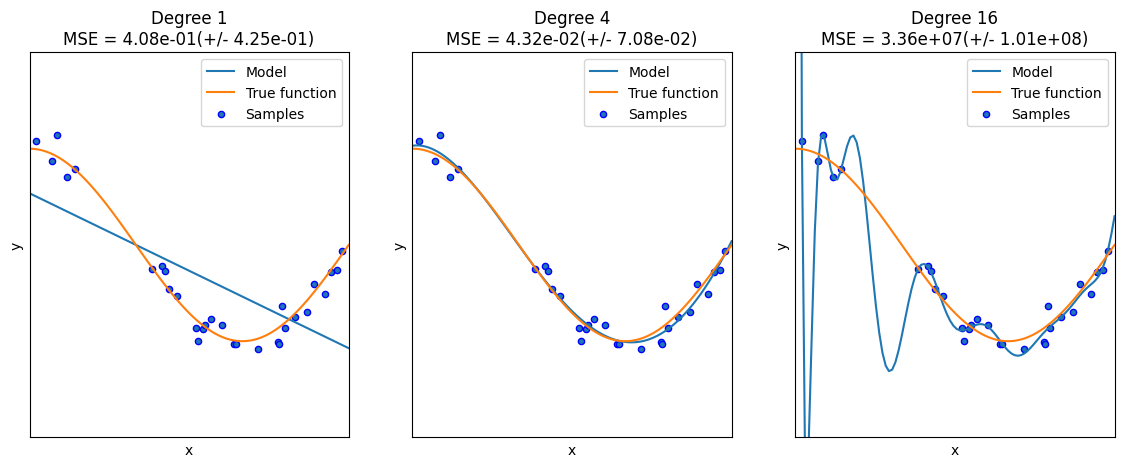

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score


def true_fun(X):
    return np.cos(1.5 * np.pi * X)

np.random.seed(0)

n_samples = 30
degrees = [1, 4, 16]

X = np.sort(np.random.rand(n_samples))
y = true_fun(X) + np.random.randn(n_samples) * 0.1

plt.figure(figsize=(14, 5))
for i in range(len(degrees)):
    ax = plt.subplot(1, len(degrees), i + 1)
    plt.setp(ax, xticks=(), yticks=())

    polynomial_features = PolynomialFeatures(degree=degrees[i],
                                             include_bias=False)
    linear_regression = LinearRegression()
    pipeline = Pipeline([("polynomial_features", polynomial_features),
                         ("linear_regression", linear_regression)])
    pipeline.fit(X[:, np.newaxis], y)
    print("Weights for degree = ", degrees[i])
    print(pipeline.named_steps["linear_regression"].coef_)
    print('\n')
    scores = cross_val_score(pipeline, X[:, np.newaxis], y,
                             scoring="neg_mean_squared_error", cv=10)
    X_test = np.linspace(0, 1, 100)
    plt.plot(X_test, pipeline.predict(X_test[:, np.newaxis]), label="Model")
    plt.plot(X_test, true_fun(X_test), label="True function")
    plt.scatter(X, y, edgecolor='b', s=20, label="Samples")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.legend(loc="best")
    plt.title("Degree {}\nMSE = {:.2e}(+/- {:.2e})".format(
        degrees[i], -scores.mean(), scores.std()))
plt.show()

## It seems that in the case of a 16th degree polynomial, the feature weights become extremely large, it means overfitting.

## Let's see what happens if we train the same model, but using the L1 regularizer:

Weights for degree =  1
[-1.48191915]


Weights for degree =  4
[-3.46734822 -0.          0.          2.27453425]


Weights for degree =  16
[-3.03536756 -0.          0.          0.          0.          2.13681585
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.        ]




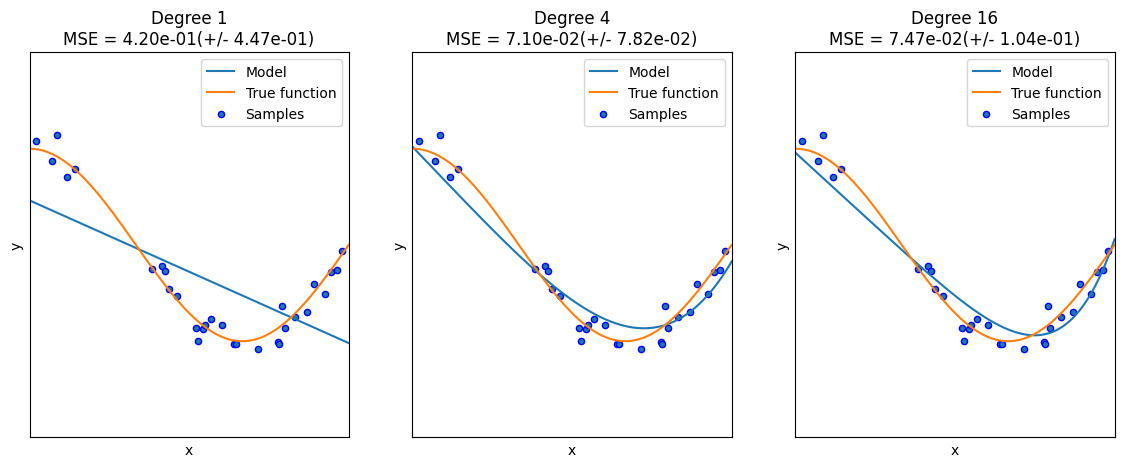

In [ ]:
np.random.seed(0)

n_samples = 30
degrees = [1, 4, 16]

X = np.sort(np.random.rand(n_samples))
y = true_fun(X) + np.random.randn(n_samples) * 0.1

plt.figure(figsize=(14, 5))
for i in range(len(degrees)):
    ax = plt.subplot(1, len(degrees), i + 1)
    plt.setp(ax, xticks=(), yticks=())

    polynomial_features = PolynomialFeatures(degree=degrees[i],
                                             include_bias=False)
    lasso_lr = Lasso(alpha = 0.01)
    pipeline = Pipeline([("polynomial_features", polynomial_features),
                         ("lasso_regression", lasso_lr)])
    pipeline.fit(X[:, np.newaxis], y)
    print("Weights for degree = ", degrees[i])
    print(pipeline.named_steps["lasso_regression"].coef_)
    print('\n')
    scores = cross_val_score(pipeline, X[:, np.newaxis], y,
                             scoring="neg_mean_squared_error", cv=10)
    X_test = np.linspace(0, 1, 100)
    plt.plot(X_test, pipeline.predict(X_test[:, np.newaxis]), label="Model")
    plt.plot(X_test, true_fun(X_test), label="True function")
    plt.scatter(X, y, edgecolor='b', s=20, label="Samples")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.legend(loc="best")
    plt.title("Degree {}\nMSE = {:.2e}(+/- {:.2e})".format(
        degrees[i], -scores.mean(), scores.std()))
plt.show()

## Conclusion:


1.   Ridge and Lasso regression models improve robustness of Linear regression through the regularization
2.   Lasso regression can shrink the weight of multicollinear features all the way to zero
3. PolynomialFeatures function (increases the order of polynom) can be used to increase the power and complexity of initial Linear model
4. Regularization helps with overfitting by suppression of redundant features

